In [ ]:
import pandas as pd
import numpy as np
import os
import torch
import seaborn as sns
import random
import pickle
import matplotlib.gridspec as gridspec
from scipy.stats import pearsonr, spearmanr
from scipy.stats import rankdata
from matplotlib import pyplot as plt
from sklearn.metrics import roc_auc_score
from sklearn.metrics import roc_curve, auc


In [12]:

# ============================================================
# Plotting
# ============================================================

METRIC_LABELS = {
    "r2": "R²",
    "spearman": "Spearman correlation",
    "auc": "ROC-AUC"
}


def clean_metric_data(df, metric):
    if metric not in METRIC_LABELS:
        raise ValueError(
            f"metric must be one of {list(METRIC_LABELS)}"
        )

    plot_df = df[
        np.isfinite(df[metric])
    ].copy()

    # Do not plot negative R² values
    if metric == "r2":
        plot_df = plot_df[
            plot_df["r2"] >= 0
        ]

    return plot_df


def add_reference_line(ax, metric):
    reference = 0.5 if metric == "auc" else 0

    ax.axhline(
        reference,
        color="black",
        linestyle="--",
        linewidth=1
    )


def get_y_limits(plot_df, metric):
    if metric == "auc":
        return 0, 1

    if metric == "spearman":
        return -1, 1

    maximum = plot_df[metric].max()

    if not np.isfinite(maximum) or maximum <= 0:
        maximum = 1

    return 0, maximum * 1.05


def set_common_y_limits(g, plot_df, metric):
    y_min, y_max = get_y_limits(
        plot_df,
        metric
    )

    for ax in g.axes.flat:
        ax.set_ylim(y_min, y_max)


def plot_half_split_violins(results):
    half_df = results[
        (results["regime"] == "random") &
        (results["train_amount_type"] == "fraction") &
        np.isclose(
            results["requested_train_amount"],
            0.5
        )
    ]

    metrics = ["r2", "spearman", "auc"]

    fig, axes = plt.subplots(
        1,
        3,
        figsize=(
            max(
                12,
                1.6 * half_df["dataset"].nunique()
            ),
            4
        )
    )

    for ax, metric in zip(axes, metrics):
        plot_df = clean_metric_data(
            half_df,
            metric
        )

        sns.violinplot(
            data=plot_df,
            x="dataset",
            y=metric,
            inner="box",
            cut=0,
            ax=ax
        )

        add_reference_line(ax, metric)
        ax.set_ylim(
            *get_y_limits(plot_df, metric)
        )
        ax.set_title(
            f"Held-out {METRIC_LABELS[metric]}"
        )
        ax.set_xlabel("")
        ax.set_ylabel(METRIC_LABELS[metric])
        ax.tick_params(
            axis="x",
            rotation=45
        )

    fig.tight_layout()
    return fig, axes


def plot_all_all_bars(results):
    all_df = results[
        results["regime"] == "all_all"
    ]

    metrics = ["r2", "spearman", "auc"]

    fig, axes = plt.subplots(
        1,
        3,
        figsize=(
            max(
                12,
                1.6 * all_df["dataset"].nunique()
            ),
            4
        )
    )

    for ax, metric in zip(axes, metrics):
        plot_df = clean_metric_data(
            all_df,
            metric
        )

        sns.barplot(
            data=plot_df,
            x="dataset",
            y=metric,
            errorbar=None,
            ax=ax
        )

        add_reference_line(ax, metric)
        ax.set_ylim(
            *get_y_limits(plot_df, metric)
        )
        ax.set_title(
            f"Train-all/test-all "
            f"{METRIC_LABELS[metric]}"
        )
        ax.set_xlabel("")
        ax.set_ylabel(METRIC_LABELS[metric])
        ax.tick_params(
            axis="x",
            rotation=45
        )

    fig.tight_layout()
    return fig, axes


def plot_fraction_panels(
    results,
    metric="r2",
    x=None,
    col_wrap=3,
    log_x=True
):
    plot_df = results[
        results["regime"] == "random"
    ].copy()

    plot_df = clean_metric_data(
        plot_df,
        metric
    )

    if x is None:
        amount_types = set(
            plot_df["train_amount_type"]
        )

        if amount_types == {"fraction"}:
            x = "train_fraction"
        else:
            x = "n_train"

    x_labels = {
        "train_fraction": "Training fraction",
        "n_train": "Number of training sequences"
    }

    g = sns.relplot(
        data=plot_df,
        x=x,
        y=metric,
        col="dataset",
        col_wrap=col_wrap,
        kind="line",
        marker="o",
        estimator="mean",
        errorbar="sd",
        facet_kws={
            "sharex": True,
            "sharey": True
        },
        height=3
    )

    for ax in g.axes.flat:
        add_reference_line(ax, metric)

        if log_x:
            ax.set_xscale("log")

    set_common_y_limits(
        g,
        plot_df,
        metric
    )

    g.set_axis_labels(
        x_labels.get(x, x),
        f"Held-out {METRIC_LABELS[metric]}"
    )
    g.set_titles("{col_name}")

    return g
def plot_mutation_panels(
    results,
    metric="r2",
    train_fractions=None,
    col_wrap=3
):
    plot_df = results[
        results["regime"] == "mutation"
    ].copy()

    if train_fractions is not None:
        plot_df = plot_df[
            plot_df[
                "requested_train_amount"
            ].isin(train_fractions)
        ]

    plot_df = clean_metric_data(
        plot_df,
        metric
    )

    plot_kwargs = {
        "data": plot_df,
        "x": "k",
        "y": metric,
        "col": "dataset",
        "col_wrap": col_wrap,
        "kind": "line",
        "marker": "o",
        "estimator": "mean",
        "errorbar": "sd",
        "facet_kws": {"sharey": True},
        "height": 3
    }

    if (
        plot_df[
            "requested_train_amount"
        ].nunique() > 1
    ):
        plot_kwargs.update({
            "hue": "requested_train_amount",
            "palette": "viridis"
        })

    g = sns.relplot(**plot_kwargs)

    for ax in g.axes.flat:
        add_reference_line(ax, metric)

    set_common_y_limits(
        g,
        plot_df,
        metric
    )

    g.set_axis_labels(
        "K: train on ≤K, test on >K",
        f"Held-out {METRIC_LABELS[metric]}"
    )
    g.set_titles("{col_name}")

    return g


In [26]:
def set_integer_x_range(ax, values):
    """Restrict an axis to the integer x-values present in its panel."""
    values = np.sort(np.unique(values))

    if len(values) == 0:
        return

    ax.set_xticks(values)

    if len(values) == 1:
        ax.set_xlim(values[0] - 0.5, values[0] + 0.5)
    else:
        ax.set_xlim(values[0] - 0.25, values[-1] + 0.25)


def plot_train_k_by_test_order(
    results,
    metric="r2",
    test_orders=range(3, 11),
    train_fraction=1.0,
    palette="tab10"
):
    """
    Panel: exact held-out test order
    x-axis: maximum training order K

    Each panel only shows K values below its test order.
    """
    plot_df = results[
        (results["regime"] == "mutation") &
        (results["test_scope"] == "exact_order") &
        (results["test_order"].isin(test_orders)) &
        np.isclose(
            results["requested_train_amount"],
            train_fraction
        )
    ].copy()

    plot_df = clean_metric_data(plot_df, metric)

    panel_orders = [
        order
        for order in test_orders
        if (plot_df["test_order"] == order).any()
    ]

    if not panel_orders:
        raise ValueError(
            "No matching exact-order results were found."
        )

    g = sns.relplot(
        data=plot_df,
        x="k",
        y=metric,
        hue="dataset",
        col="test_order",
        col_order=panel_orders,
        col_wrap=None,
        kind="line",
        marker="o",
        estimator="mean",
        errorbar="sd",
        palette=palette,
        facet_kws={
            "sharex": False,
            "sharey": True
        },
        height=3,
        aspect=1.1
    )

    for ax, test_order in zip(g.axes.flat, panel_orders):
        panel_df = plot_df[
            plot_df["test_order"] == test_order
        ]

        set_integer_x_range(
            ax,
            panel_df["k"]
        )
        add_reference_line(ax, metric)

    set_common_y_limits(g, plot_df, metric)

    g.set_axis_labels(
        "Maximum training mutation order K",
        METRIC_LABELS[metric]
    )
    g.set_titles(
        "Exact test order = {col_name}"
    )

    return g


def plot_test_order_by_train_k(
    results,
    metric="r2",
    train_ks=range(1, 7),
    train_fraction=1.0,
    palette="tab10"
):
    """
    Panel: maximum training order K
    x-axis: exact held-out test order

    Each panel only shows test orders that are above its K.
    """
    plot_df = results[
        (results["regime"] == "mutation") &
        (results["test_scope"] == "exact_order") &
        (results["k"].isin(train_ks)) &
        np.isclose(
            results["requested_train_amount"],
            train_fraction
        )
    ].copy()

    plot_df = clean_metric_data(plot_df, metric)

    panel_ks = [
        k
        for k in train_ks
        if (plot_df["k"] == k).any()
    ]

    if not panel_ks:
        raise ValueError(
            "No matching exact-order results were found."
        )

    g = sns.relplot(
        data=plot_df,
        x="test_order",
        y=metric,
        hue="dataset",
        col="k",
        col_order=panel_ks,
        col_wrap=None,
        kind="line",
        marker="o",
        estimator="mean",
        errorbar="sd",
        palette=palette,
        facet_kws={
            "sharex": False,
            "sharey": True
        },
        height=3,
        aspect=1.1
    )

    for ax, k in zip(g.axes.flat, panel_ks):
        panel_df = plot_df[
            plot_df["k"] == k
        ]

        set_integer_x_range(
            ax,
            panel_df["test_order"]
        )
        add_reference_line(ax, metric)

    set_common_y_limits(g, plot_df, metric)

    g.set_axis_labels(
        "Exact test mutation order",
        METRIC_LABELS[metric]
    )
    g.set_titles(
        "Train on mutation orders ≤ {col_name}"
    )

    return g

In [29]:
results = pd.read_csv("/home/labs/fleishman/itayta/new_fitness_repo/fitness_learning/notebooks/data/merged_datasets/linear_baslines/gfp_tmp.csv")

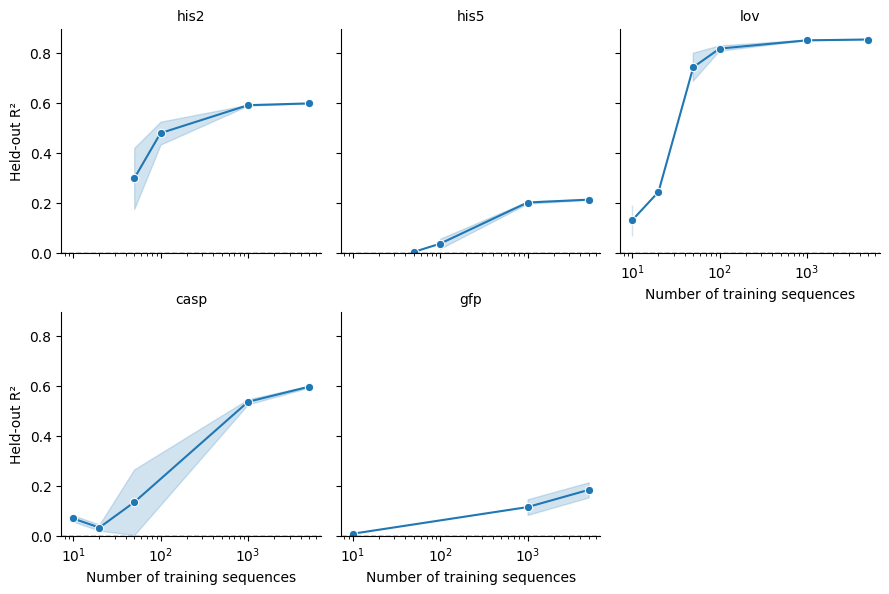

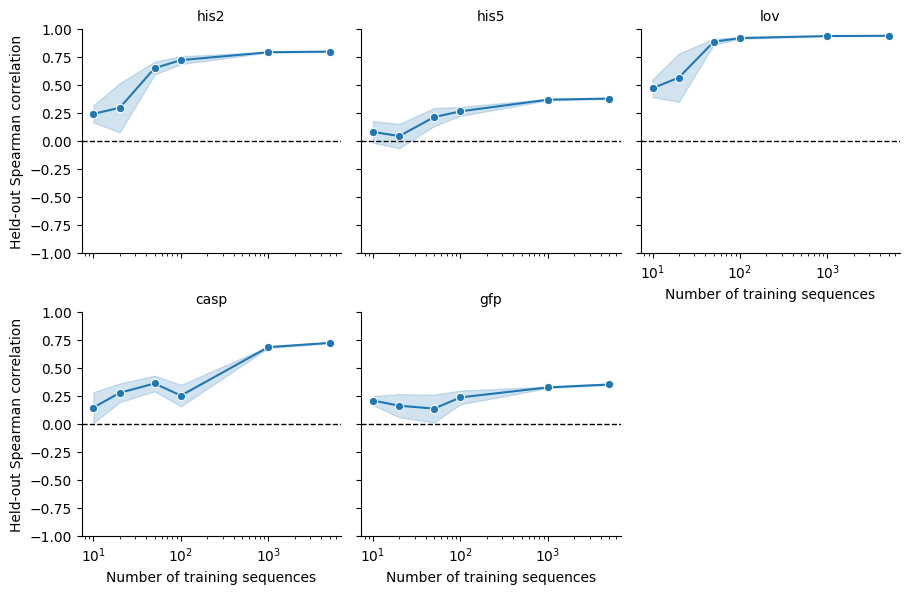

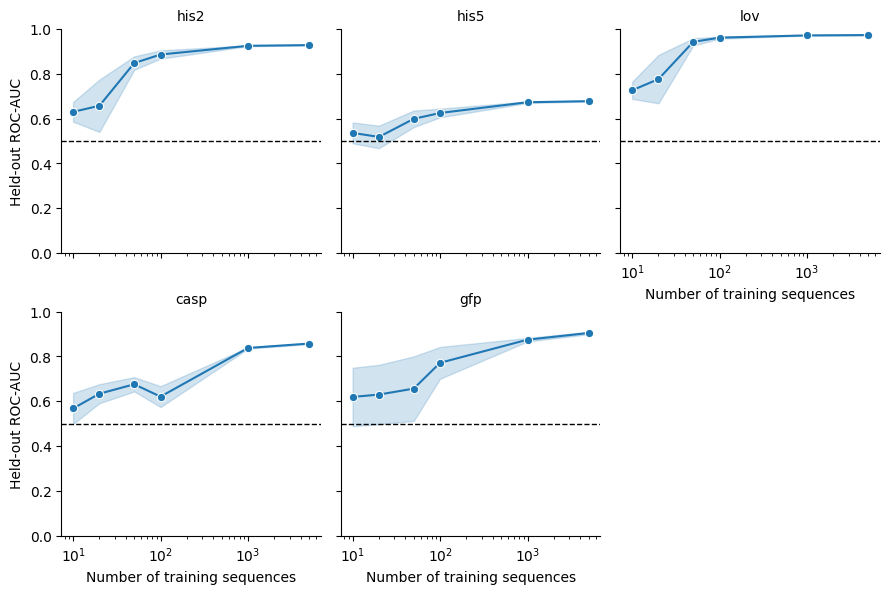

In [30]:

plot_fraction_panels(
    results,
    metric="r2"
)
plt.show()

plot_fraction_panels(
    results,
    metric="spearman"
)
plt.show()

plot_fraction_panels(
    results,
    metric="auc"
)
plt.show()

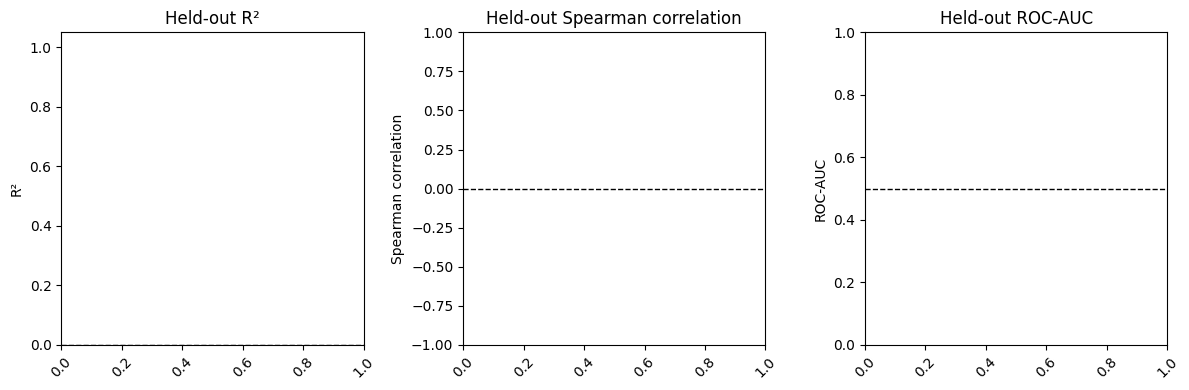

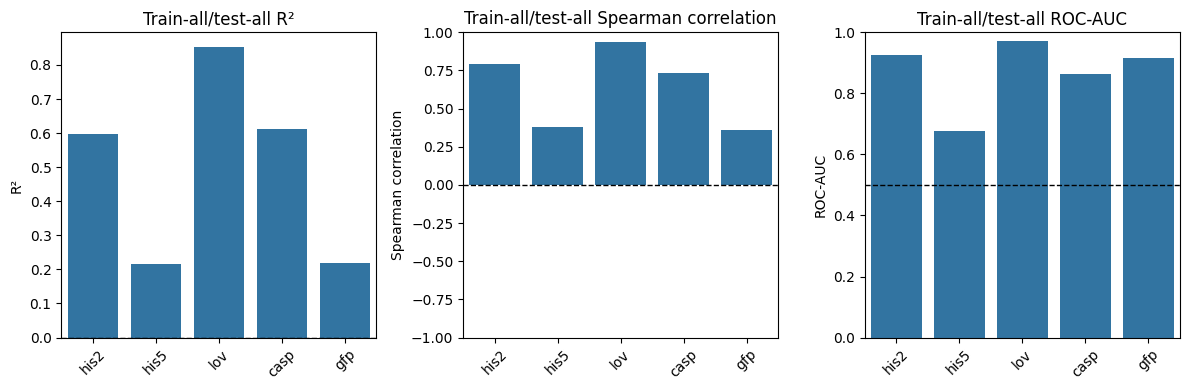

In [31]:
# 1. Violin plots for random 50/50 splits
fig, axes = plot_half_split_violins(results)
plt.show() 

# 4. Train-all/test-all bar plots
fig, axes = plot_all_all_bars(results)
plt.show()

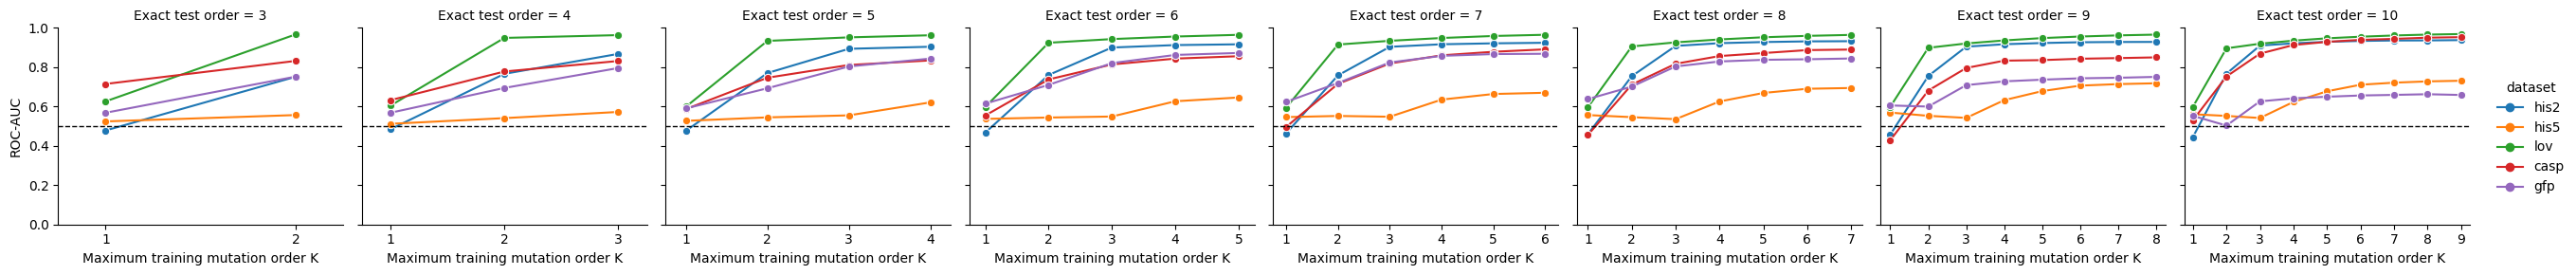

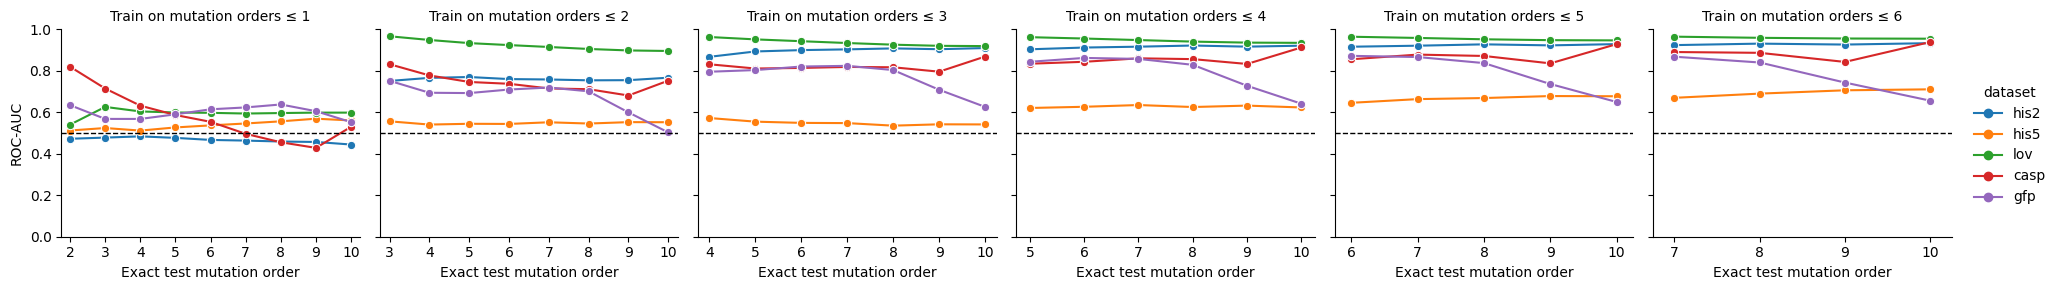

In [32]:
plot_train_k_by_test_order(
    results,
    metric="auc",
    #col_wrap=None,
)
plt.show()

plot_test_order_by_train_k(
    results,
    metric="auc",
    #col_wrap=None,
)
plt.show()